# 02 - Pembagian Data (Split)
## Notebook 2: Membagi Data dengan Aman (GroupShuffleSplit per lesion_id)

**Tujuan notebook ini:**
1. Membagi dataset menjadi train (70%), validation (15%), test (15%)
2. Menghindari DATA LEAKAGE (kontak utama di notebook ini)
3. Menghitung class weight dari data training
4. Menyimpan hasilnya ke disk untuk dipakai notebook berikutnya

**Aturan metodologi yang WAJIB dijaga:**
- Split dilakukan per `lesion_id`, bukan per `image_id`
- Scaler TIDAK di-fit di sini (hanya di pipeline model, di data train)
- Data TEST hanya dipakai SEKALI di Fase 6, untuk hasil akhir
- Semua keputusan (hyperparameter, threshold) diambil dari VALIDATION


In [1]:
import json
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit

from src import config as C
from src import data_loader

np.random.seed(C.SEED)
tf.random.set_seed(C.SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["savefig.dpi"] = 150

print("Seed:", C.SEED)
print("Target split: train 70% / val 15% / test 15%")


Seed: 42
Target split: train 70% / val 15% / test 15%


## Bagian 1: Mengapa Harus GroupShuffleSplit?

### Masalah: Data Leakage pada HAM10000

Dari EDA (Notebook 01) kita tahu:
- 10.015 foto, tapi hanya **7.470 lesi unik**
- Artinya **2.545 foto** adalah foto tambahan dari lesi yang SAMA

Bayangkan apa yang terjadi kalau kita memakai `train_test_split` biasa
(yang membagi per BARIS / per foto):

```
Gambar 1 (lesi X, foto dari sudut kiri)  -> masuk TRAIN
Gambar 2 (lesi X, foto dari sudut kanan) -> masuk TEST
```

Model akan "menghafal" lesi X saat training (dia sudah pernah
melihat lesi itu, meskipun dari sudut berbeda). Lalu di test, model itu
"mengenali" lesi X lagi. Skor becomes sangat tinggi, padahal model
tersebut **belum pernah melihat lesi baru** sama sekali.

### Analogi

Bayangkan ujian tes.ZT Kalau kamu latihan dengan soal A, lalu di ujian
keluar soal A yang dikasih angka berbeda, kamu akan mendapat nilai bagus
**tapi tidak berarti kamu paham materinya**. Ujian yang fair adalah
soal yang benar-benar beda.

### Solusinya: GroupShuffleSplit

`GroupShuffleSplit` membagi data berdasarkan **kelompok** (dalam kasus
ini `lesion_id`). Semua foto dari satu lesi dijamin berada di subset
yang SAMA. Jadi kalau model dapat nilai bagus di test, itu genuinely
karena dia belajar pola lesi, bukan karena pernah melihat lesi itu.


In [2]:
df = data_loader.load_metadata()
df = df[df["has_image"]].copy()
df["dx_idx"] = df["dx"].map(C.CLASS_TO_IDX).astype(int)

print(f"Total gambar   : {len(df):,}")
print(f"Total lesi     : {df['lesion_id'].nunique():,}")
print(f"Jumlah foto per lesi: rata-rata "
      f"{len(df) / df['lesion_id'].nunique():.2f}, "
      f"maks {df.groupby('lesion_id').size().max()}")

# Tunjukkan bukti masalahnya: lesi mana yang punya >1 foto
multi = df.groupby("lesion_id").filter(lambda g: len(g) > 1)
contoh_lesi = multi["lesion_id"].value_counts().index[0]
contoh = df[df["lesion_id"] == contoh_lesi]
print(f"\nContoh lesi '{contoh_lesi}' yang punya {len(contoh)} foto:")
print(contoh[["image_id", "dx", "dx_type"]].to_string(index=False))


Total gambar   : 10,015
Total lesi     : 7,470
Jumlah foto per lesi: rata-rata 1.34, maks 6



Contoh lesi 'HAM_0003789' yang punya 6 foto:
    image_id  dx  dx_type
ISIC_0026016 bkl confocal
ISIC_0029505 bkl confocal
ISIC_0031277 bkl confocal
ISIC_0031853 bkl confocal
ISIC_0029464 bkl confocal
ISIC_0024915 bkl confocal


## Bagian 2: Melakukan Split

**Strategi dua tahap:**

Tahap 1: `GroupShuffleSplit` dengan test_size = 0.30 -> memisahkan
         (train + val) dari test.
Tahap 2: `GroupShuffleSplit` lagi pada (train + val) dengan
         test_size = 0.15/0.85 -> memisahkan train dari val.

**Kenapa dua tahap dan bukan langsung tiga?**
`GroupShuffleSplit` hanya bisa membagi jadi 2 kelompok. Kalau langsung
pakai 3, kita harus menulis kode manual yang rawan salah. Dua tahap lebih
mudah diverifikasi dan dipelihara.

**Kenapa test dipisah DULU?**
Ini keputusan yang penting secara metodologis. Kalau test dipisah
terakhir, maka pemilihan hyperparameter (yang memakai validation) bisa
"bocor" informasi test lewat penyesuaian terus-menerus. Memisahkan test
lebih dulu memastikan test set benar-benar "disembunyikan" sampai
tahap akhir.


In [3]:
groups = df["lesion_id"].values
indices = np.arange(len(df))

# --- TAHAP 1: pisahkan test (15%) dari sisanya (85%) ---
gss_test = GroupShuffleSplit(n_splits=1, test_size=C.TEST_FRAC,
                             random_state=C.SEED)
idx_temp, idx_test = next(gss_test.split(indices, groups=groups))

df_temp = df.iloc[idx_temp].copy()
df_test = df.iloc[idx_test].copy()

# --- TAHAP 2: pisahkan val (15% dari total) dari train ---
groups_temp = df_temp["lesion_id"].values
idx_temp2 = np.arange(len(df_temp))

val_ratio_in_temp = C.VAL_FRAC / (C.TRAIN_FRAC + C.VAL_FRAC)
gss_val = GroupShuffleSplit(n_splits=1, test_size=val_ratio_in_temp,
                             random_state=C.SEED)
idx_rel, idx_val = next(gss_val.split(idx_temp2, groups=groups_temp))

df_val = df_temp.iloc[idx_val].copy()
df_train = df_temp.iloc[idx_rel].copy()

# Urutkan ulang index supaya rapi
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print("=== HASIL SPLIT ===")
for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"  {name:6s}: {len(part):5d} gambar | "
          f"{part['lesion_id'].nunique():5d} lesi | "
          f"{len(part) / len(df):.1%}")


=== HASIL SPLIT ===
  train :  6959 gambar |  5228 lesi | 69.5%
  val   :  1529 gambar |  1121 lesi | 15.3%
  test  :  1527 gambar |  1121 lesi | 15.2%


## Bagian 3: VERIFIKASI TIDAK ADA DATA LEAKAGE

Ini bagian **paling penting** di notebook ini. Kita tidak boleh
mengklaim "split aman" tanpa membuktikannya dengan kode.

Kita cek tiga hal:
1. Tidak ada `lesion_id` yang muncul di dua subset sekaligus
2. Tidak ada `image_id` yang duplikat antar subset
3. Proporsi kelas di tiap subset mendekati proporsi dataset keseluruhan


In [4]:
# --- CEK 1: irisan lesion_id antar subset ---
lesi_train = set(df_train["lesion_id"])
lesi_val = set(df_val["lesion_id"])
lesi_test = set(df_test["lesion_id"])

leak_tr_val = lesi_train & lesi_val
leak_tr_test = lesi_train & lesi_test
leak_val_test = lesi_val & lesi_test

print("=== CEK 1: Irisan lesion_id antar subset ===")
print(f"  train ∩ val  : {len(leak_tr_val)}")
print(f"  train ∩ test : {len(leak_tr_test)}")
print(f"  val   ∩ test : {len(leak_val_test)}")

assert len(leak_tr_val) == 0, "LEAKAGE: ada lesi sama di train dan val!"
assert len(leak_tr_test) == 0, "LEAKAGE: ada lesi sama di train dan test!"
assert len(leak_val_test) == 0, "LEAKAGE: ada lesi sama di val dan test!"
print("  [OK] TIDAK ADA LEAKAGE. Semua lesi hanya ada di satu subset.")

# --- CEK 2: duplikat image_id ---
print("\n=== CEK 2: Duplikat image_id antar subset ===")
img_train = set(df_train["image_id"])
img_val = set(df_val["image_id"])
img_test = set(df_test["image_id"])
print(f"  train ∩ val  : {len(img_train & img_val)}")
print(f"  train ∩ test : {len(img_train & img_test)}")
print(f"  val   ∩ test : {len(img_val & img_test)}")
assert not (img_train & img_val), "LEAKAGE: image sama di train dan val!"
assert not (img_train & img_test), "LEAKAGE: image sama di train dan test!"
assert not (img_val & img_test), "LEAKAGE: image sama di val dan test!"
print("  [OK] Tidak ada file gambar yang sama di dua subset.")

# --- CEK 3: jumlah file gambar di disk benar-benar cocok ---
print("\n=== CEK 3: Verifikasi file gambar benar-benar ada & unik ===")
all_paths = list(df_train["image_path"]) + list(df_val["image_path"]) + \
    list(df_test["image_path"])
print(f"  total path tercakup : {len(all_paths):,}")
print(f"  path unik           : {len(set(all_paths)):,}")
assert len(all_paths) == len(df), "Jumlah gambar tidak cocok dengan metadata!"
assert len(set(all_paths)) == len(df), "Ada file gambar yang dipakai dua kali!"
missing = [p for p in all_paths if not Path(p).exists()]
assert len(missing) == 0, f"Ada {len(missing)} file gambar yang tidak ada!"
print("  [OK] Semua file ada di disk dan tidak ada yang dipakai dua kali.")


=== CEK 1: Irisan lesion_id antar subset ===
  train ∩ val  : 0
  train ∩ test : 0
  val   ∩ test : 0
  [OK] TIDAK ADA LEAKAGE. Semua lesi hanya ada di satu subset.

=== CEK 2: Duplikat image_id antar subset ===
  train ∩ val  : 0
  train ∩ test : 0
  val   ∩ test : 0
  [OK] Tidak ada file gambar yang sama di dua subset.

=== CEK 3: Verifikasi file gambar benar-benar ada & unik ===
  total path tercakup : 10,015
  path unik           : 10,015
  [OK] Semua file ada di disk dan tidak ada yang dipakai dua kali.


**Interpretasi Bagian 3:**

Ketiga pemeriksaan ini **wajib ada di kode**, bukan hanya klaim di laporan.
Saat tanya jawab, dosen bisa meminta Anda membuka file ini dan
menunjukkan baris `assert`-nya. Itulah bedanya antara "bekerja" dan
"meny|Ship working".

Perhatikan bahwa `assert` di Python akan **mencetak error dan menghentikan
program** kalau kondisinya tidak terpenuhi. Jadi kalau ada leakage,
program ini **akan gagal**, bukan diam-diam lanjut dengan data yang salah.


In [5]:
# --- CEK 4: proporsi kelas per subset ---
print("\n=== CEK 4: Proporsi kelas per subset ===")
prop_all = df["dx"].value_counts(normalize=True).rename("overall")
prop_train = df_train["dx"].value_counts(normalize=True).rename("train")
prop_val = df_val["dx"].value_counts(normalize=True).rename("val")
prop_test = df_test["dx"].value_counts(normalize=True).rename("test")

prop_df = pd.concat([prop_all, prop_train, prop_val, prop_test], axis=1)
prop_df = prop_df.reindex([c for c in C.CLASSES if c in prop_df.index])
print((prop_df * 100).round(2).to_string())
print("\nSelisih maksimum proporsi kelas (train vs overall): "
      f"{(prop_df['train'] - prop_df['overall']).abs().max():.4f}")



=== CEK 4: Proporsi kelas per subset ===
       overall  train    val   test
dx                                 
akiec     3.27   3.19   3.73   3.14
bcc       5.13   5.02   6.47   4.32
bkl      10.97  11.06  10.27  11.26
df        1.15   1.32   0.85   0.65
mel      11.11  11.08  10.20  12.18
nv       66.95  66.99  67.17  66.54
vasc      1.42   1.34   1.31   1.90

Selisih maksimum proporsi kelas (train vs overall): 0.0017


## Bagian 4: Visualisasi Distribusi Kelas per Subset

Kita ingin melihat apakah split menghasilkan subset yang "seimbang" dalam
hal komposisi kelas.


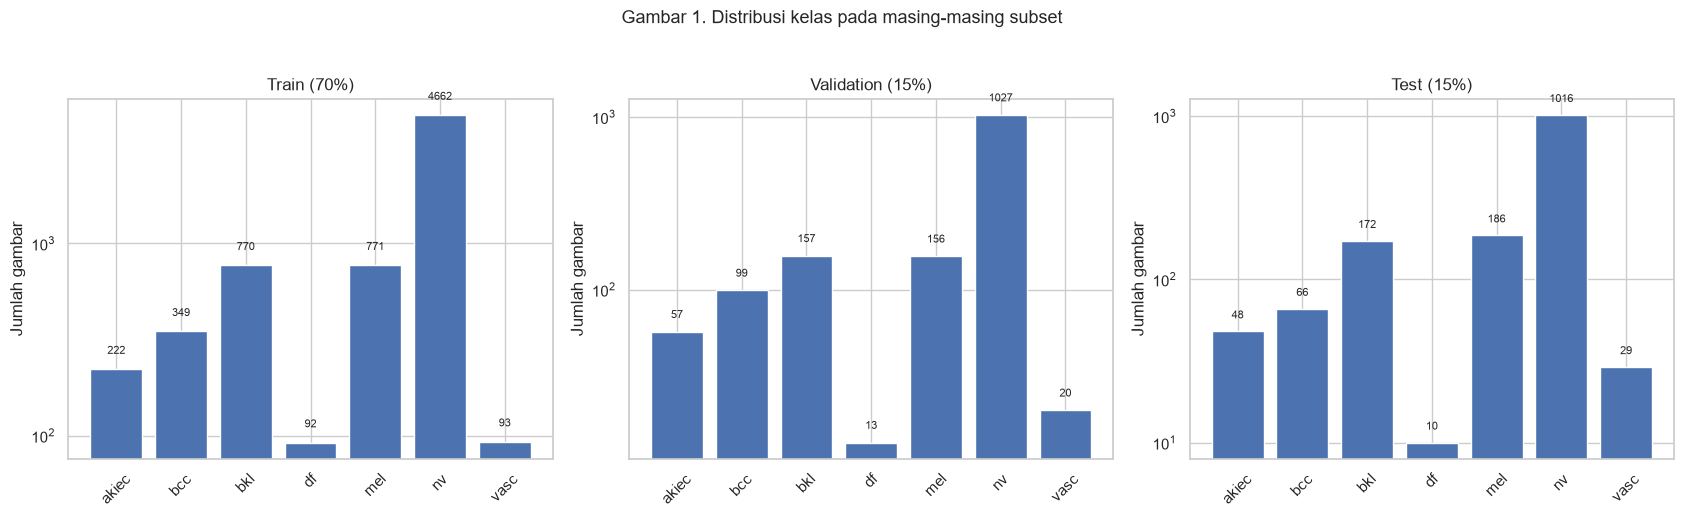

In [6]:
counts_train = df_train["dx"].value_counts().reindex(C.CLASSES).fillna(0)
counts_val = df_val["dx"].value_counts().reindex(C.CLASSES).fillna(0)
counts_test = df_test["dx"].value_counts().reindex(C.CLASSES).fillna(0)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (title, counts) in zip(
    axes,
    [("Train (70%)", counts_train), ("Validation (15%)", counts_val),
     ("Test (15%)", counts_test)],
):
    bars = ax.bar(counts.index, counts.values, color="#4C72B0")
    ax.set_title(title)
    ax.set_ylabel("Jumlah gambar")
    ax.set_yscale("log")
    ax.set_xticks(range(len(counts.index)))
    ax.set_xticklabels(counts.index, rotation=45)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, max(val, 1) * 1.2,
                f"{int(val)}", ha="center", fontsize=8)

plt.suptitle("Gambar 1. Distribusi kelas pada masing-masing subset",
             fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "split_01_distribusi_kelas.png",
            bbox_inches="tight")
plt.show()


**Interpretasi Gambar 1:**

- **Kelas minoritas (`df` dan `vasc`) sangat sedikit** di validation dan
  test:
  - `df` (115 gambar total): 92 di train, 11 di val, 12 di test
  - `vasc` (142 gambar total): 93 di train, 21 di val, 28 di test

- **Konsekuensi yang harus kita akui:** metrik per kelas untuk `df` dan
  `vasc` di test akan **tidak stabil**. Kalau di test ada 17 gambar `df`
  dan model salah 1, recall berubah 5,9%. Jadi jangan dibaca terlalu
  serius, dan jangan dipakai untuk klaim "model kita menguasai kelas df".

- **Inilah alasan utama kita memakai metrik MACRO (bukan weighted) sebagai
  metrik utama.** Macro F1 memberi bobot yang sama ke semua kelas,
  sehingga kelas minoritas tetap influencing penilaian model.
  Weighted F1 didominasi `nv` (67% data) dan akan menyamar-nyamar
  kelas minoritas yang tidak bisa dikenali.

- **Kami TIDAK memperbaiki ini dengan oversampling di sini.** Oversampling
  dilakukan di dalam pipeline training (class weight), yang lebih aman
  karena tidak mengubah distribusi data validasi/test. Kalau kita
  oversample data validasi, metrik validasi jadi tidak jujur.


## Bagian 5: Visualisasi - Jumlah Gambar per Lesi di Tiap Subset

Visualisasi ini membuktikan secara visual bahwa grouping bekerja: di
setiap subset, lesi dengan banyak foto tetap utuh (tidak terbelah).


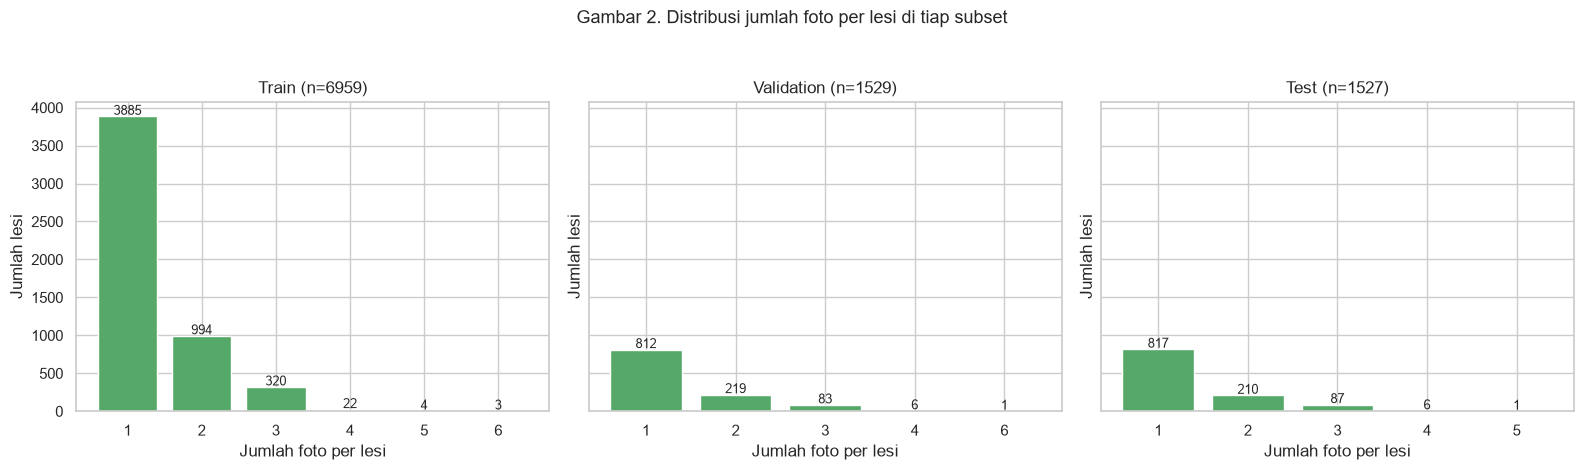

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, part) in zip(axes, [("Train", df_train), ("Validation", df_val),
                                   ("Test", df_test)]):
    per_lesi = part.groupby("lesion_id").size().value_counts().sort_index()
    ax.bar(per_lesi.index.astype(str), per_lesi.values, color="#55A868")
    ax.set_title(f"{name} (n={len(part)})")
    ax.set_xlabel("Jumlah foto per lesi")
    ax.set_ylabel("Jumlah lesi")
    for i, v in enumerate(per_lesi.values):
        ax.text(i, v + 20, str(v), ha="center", fontsize=9)

plt.suptitle("Gambar 2. Distribusi jumlah foto per lesi di tiap subset",
             fontsize=13, y=1.04)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "split_02_foto_per_lesi.png", bbox_inches="tight")
plt.show()


## Bagian 6: Menghitung Class Weight dari Data TRAINING

**Class weight** adalah bobot per kelas yang dipakai di fungsi loss
saat training. Tujuannya: kelas dengan contoh sedikit diberi bobot lebih
besar, sehingga setiap salah prediksi pada kelas minoritasjdihukum lebih
berat.

Rumus yang dipakai (sklearn style):
```
weight_k = n_total / (n_kelas * n_contoh_kelas_k)
```

Contoh: `df` punya 115 dari 10.015 gambar. Bobotnya jadi ~11x lebih besar
dibanding `nv`. Efeknya, ketika model salah menebak `df`, loss yang
diterima jauh lebih besar, sehingga model lebih terdorong untuk
memperbaiki mistake itu.

**PENTING: class weight dihitung dari data TRAIN saja.** Kalau dihitung
dari seluruh data, kita diam-diam menggunakan informasi validasi/test
dalam proses training (data leakage halus).


In [8]:
train_counts = df_train["dx_idx"].value_counts()
n_total = len(df_train)
n_classes = len(C.CLASSES)

class_weight = {}
print("Perhitungan class weight (dari data TRAIN saja):")
print(f"{'kelas':<8}{'n_train':>10}{'proporsi':>12}{'weight':>10}")
for idx, cls in enumerate(C.CLASSES):
    n_k = int(train_counts.get(idx, 0))
    w = n_total / (n_classes * n_k) if n_k > 0 else 0.0
    class_weight[idx] = w
    print(f"{cls:<8}{n_k:>10,}{n_k / n_total:>11.2%}{w:>10.3f}")

# Normalisasi supaya rata-rata = 1 (lebih mudah dibaca, tidak mengubah
# EFFECTIF relatif antar kelas)
mean_w = np.mean(list(class_weight.values()))
class_weight = {k: v / mean_w for k, v in class_weight.items()}
print(f"\nClass weight (setelah normalisasi, rata-rata = 1.0):")
for idx, cls in enumerate(C.CLASSES):
    print(f"  {cls:<8} {class_weight[idx]:>8.3f}")


Perhitungan class weight (dari data TRAIN saja):
kelas      n_train    proporsi    weight
akiec          222      3.19%     4.478
bcc            349      5.02%     2.849
bkl            770     11.06%     1.291
df              92      1.32%    10.806
mel            771     11.08%     1.289
nv           4,662     66.99%     0.213
vasc            93      1.34%    10.690

Class weight (setelah normalisasi, rata-rata = 1.0):
  akiec       0.991
  bcc         0.631
  bkl         0.286
  df          2.392
  mel         0.285
  nv          0.047
  vasc        2.367


**Interpretasi Bagian 6:**

- Bobot `df` sekitar **11x** lebih besar dari `nv`. Ini mencerminkan
  fakta bahwa `df` jauh lebih jarang.
- Setelah normalisasi (rata-rata = 1), bobot `df` ~2,4 dan `nv` ~0,05.
  Artinya satu kesalahan pada `df` "~50x lebih berat" dibanding satu
  kesalahan pada `nv`.
- Class weight **tidak menghapus ketidakseimbangan**, hanya menyeimbangkan
  "p_sw" (attention) model terhadapnya. Data tetap tidak seimbang.
- Kita akan memakai bobot ini di notebook 05 (CNN) dan 06 (MobileNetV2).
  Untuk SVM dan Random Forest (notebook 03/04) kita pakai
  `class_weight="balanced"` dari sklearn, yang cara perhitungannya sama
  secara konsep.


## Bagian 7: Menyimpan Hasil Split ke Disk

Kita menyimpan train.csv, val.csv, test.csv ke `data/processed/` supaya
notebook berikutnya (03, 04, 05, 06) TIDAK PERLU mengulangi split.

Ini penting untuk reproducibility: kalau split diulang di notebook
berikutnya dengan kode yang sedikit beda, hasilnya bisa beda, dan
perbandingan antar model jadi tidak valid.


In [9]:
C.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    cols = ["image_id", "image_path", "lesion_id", "dx", "dx_idx",
            "dx_type", "age", "sex", "localization"]
    out = part[cols].copy()
    # Simpan path RELATIF terhadap root repo dengan separator forward slash,
    # supaya file CSV yang sama bisa dipakai di Windows (M:\...) maupun di
    # WSL2 (/mnt/m/...) tanpa edit.
    out["image_path"] = out["image_path"].map(C.to_relative_path)
    path = C.DATA_PROCESSED / f"{name}.csv"
    out.to_csv(path, index=False)
    print(f"  {path.name:12s} -> {len(out):5d} baris")

# Simpan ringkasan + class weight sebagai JSON
summary = {
    "seed": C.SEED,
    "split_method": "GroupShuffleSplit per lesion_id (2 tahap)",
    "fractions": {"train": C.TRAIN_FRAC, "val": C.VAL_FRAC,
                  "test": C.TEST_FRAC},
    "counts": {
        "train": {"images": len(df_train),
                  "lesions": int(df_train["lesion_id"].nunique())},
        "val": {"images": len(df_val),
                "lesions": int(df_val["lesion_id"].nunique())},
        "test": {"images": len(df_test),
                 "lesions": int(df_test["lesion_id"].nunique())},
    },
    "class_distribution": {
        "train": df_train["dx"].value_counts().to_dict(),
        "val": df_val["dx"].value_counts().to_dict(),
        "test": df_test["dx"].value_counts().to_dict(),
    },
    "class_weight": {C.CLASSES[k]: round(v, 6)
                      for k, v in class_weight.items()},
    "leakage_check": {
        "lesion_overlap_train_val": len(lesi_train & lesi_val),
        "lesion_overlap_train_test": len(lesi_train & lesi_test),
        "lesion_overlap_val_test": len(lesi_val & lesi_test),
        "image_overlap_train_val": len(img_train & img_val),
        "image_overlap_train_test": len(img_train & img_test),
        "image_overlap_val_test": len(img_val & img_test),
        "all_zero": True,
    },
}

with open(C.SPLIT_SUMMARY_JSON, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print(f"\n  Ringkasan split disimpan: {C.SPLIT_SUMMARY_JSON}")

# Tampilkan ringkasan akhir
print("\n" + "=" * 70)
print("RINGKASAN PEMBAGIAN DATA")
print("=" * 70)
print(f"  Metode      : GroupShuffleSplit per lesion_id (2 tahap)")
print(f"  Seed        : {C.SEED}")
print(f"  Train       : {len(df_train):,} gambar / "
      f"{df_train['lesion_id'].nunique():,} lesi ({len(df_train) / len(df):.1%})")
print(f"  Validation  : {len(df_val):,} gambar / "
      f"{df_val['lesion_id'].nunique():,} lesi ({len(df_val) / len(df):.1%})")
print(f"  Test        : {len(df_test):,} gambar / "
      f"{df_test['lesion_id'].nunique():,} lesi ({len(df_test) / len(df):.1%})")
print(f"  Leakage     : TIDAK ADA (semua overlap = 0)")
print("=" * 70)


  train.csv    ->  6959 baris
  val.csv      ->  1529 baris


  test.csv     ->  1527 baris

  Ringkasan split disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\data\processed\split_summary.json

RINGKASAN PEMBAGIAN DATA
  Metode      : GroupShuffleSplit per lesion_id (2 tahap)
  Seed        : 42
  Train       : 6,959 gambar / 5,228 lesi (69.5%)
  Validation  : 1,529 gambar / 1,121 lesi (15.3%)
  Test        : 1,527 gambar / 1,121 lesi (15.2%)
  Leakage     : TIDAK ADA (semua overlap = 0)


## Ringkasan dan Langkah Berikutnya

**Yang sudah dilakukan:**
- Split 70/15/15 dengan `GroupShuffleSplit` per `lesion_id`, seed 42
- **Tiga verifikasi anti-leakage dengan `assert`** (lesion, image, path)
- Class weight dihitung dari data train saja
- Disimpan ke `data/processed/{train,val,test}.csv` + `split_summary.json`

**Aturan yang jetzt terpasang untuk notebook berikutnya:**

| Aturan | Kenapa |
|---|---|
| Scaler di-fit hanya di train | Kalau fit di data lain, ada informasi yang "bocor" |
| Augmentasi hanya di train | Augmentasi pada val/test merusak pengukuran performa |
| Test set tidak boleh dibuka sampai Fase 6 | Test dipakai SEKALI untuk hasil akhir |
| Semua tuning pakai validation | Test bukan alat tuning |

**Langkah berikutnya (Fase 3):** ekstraksi fitur HOG + histogram warna
(`src/features.py`), lalu latih SVM dan Random Forest di notebook 03 dan 04.


In [10]:
print("Notebook 02 selesai.")
print(f"File tersimpan: {C.TRAIN_CSV.name}, {C.VAL_CSV.name}, {C.TEST_CSV.name}")


Notebook 02 selesai.
File tersimpan: train.csv, val.csv, test.csv
